# Career Guidance Support Chatbot — NLP Final Project

**Dataset:** [`Pradeep016/career-guidance-qa-dataset`](https://huggingface.co/datasets/Pradeep016/career-guidance-qa-dataset) (Hugging Face Hub)
**Deliverables:** this notebook (training, evaluation, analysis) and `app.py` (Streamlit demo that loads the model trained here).

### Contents
1. Project overview and objectives
2. Imports and environment verification
3. Downloading and loading the dataset
4. Dataset structure and data-quality inspection
5. Exploratory data analysis
6. Text cleaning and NLP preprocessing
7. Train/test split and data-leakage prevention
8. Feature extraction with TF-IDF
9. Model development: approach
10. Question–answer retrieval with cosine similarity
11. Classification models (role and intent)
12. Response selection, thresholds and fallback responses
13. Model evaluation on the held-out test set (+ saving the final model)
14. Sample chatbot conversations
15. Error analysis, limitations and improvements
16. NLP pipeline diagram
17. Conclusion

> Every number in this notebook is produced by the code cells; nothing is typed in by hand.

## 1. Project overview and objectives

People exploring careers ask the same kinds of questions — *What does this job involve? What skills
do I need? What does it pay? How do I get started?* — in many different wordings. The goal of this
project is a chatbot that understands such a question and replies with a reliable answer from a
curated knowledge base, and that **admits when it does not know** instead of guessing.

**Objectives**
1. Load and inspect a real career-guidance QA dataset, and verify its structure instead of assuming it.
2. Build an NLP pipeline: text preprocessing → feature extraction (TF-IDF, plus sentence embeddings for comparison) → machine-learning models.
3. Combine **classification** (which career? which topic?) with **cosine-similarity retrieval** (which stored answer?).
4. Add confidence/similarity thresholds that trigger clarification or fallback responses.
5. Evaluate honestly on questions whose *wording* was never seen in training, and analyse the errors.
6. Save the trained pipeline so the Streamlit app (`app.py`) uses exactly the same model.

All reusable logic (preprocessing, model, response selection) lives in `chatbot_core.py`, which both
this notebook and `app.py` import — so what is evaluated here is exactly what the app runs.

## 2. Imports and environment verification

In [1]:
import os, sys, platform, re, time, json, warnings
from pathlib import Path
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")   # harmless Windows cache warning
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch
import seaborn as sns
import sklearn, nltk, datasets, sentence_transformers, torch
from datasets import load_dataset
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, log_loss)

import chatbot_core as cc
from chatbot_core import CareerChatbot, Thresholds, TextPreprocessor, INTENTS, INTENT_NAMES

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 160)

# Chart styling: one validated palette (blue = primary series, orange = comparison series).
BLUE, ORANGE, INK, INK2, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e1e0d9"
SEQ_BLUES = LinearSegmentedColormap.from_list("seq_blue", ["#fcfcfb", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 12, "figure.dpi": 100,
})

versions = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "nltk": nltk.__version__, "datasets": datasets.__version__,
            "sentence-transformers": sentence_transformers.__version__, "torch": torch.__version__,
            "matplotlib": matplotlib.__version__, "seaborn": sns.__version__}
print("Interpreter:", sys.executable)
pd.Series(versions, name="version").to_frame()

Interpreter: C:\Users\Acete\OneDrive\Desktop\Career Guidance  Support\.venv\Scripts\python.exe


,version
python,3.14.7
numpy,2.5.4
pandas,3.0.6
scikit-learn,1.9.1
nltk,3.10.3
datasets,5.1.0
sentence-transformers,6.1.0
torch,2.14.1+cpu
matplotlib,3.11.2
seaborn,0.13.2


## 3. Downloading and loading the Hugging Face dataset

`datasets.load_dataset` downloads the dataset from the Hugging Face Hub on the first run and then
re-uses the local cache (`~/.cache/huggingface`).

In [2]:
ds = load_dataset(cc.DATASET_ID)
print(ds)
raw = ds["train"].to_pandas()
raw.head()

DatasetDict({
    train: Dataset({
        features: ['role', 'question', 'answer'],
        num_rows: 1620
    })
})


,role,question,answer
0,Data Scientist,What does a Data Scientist do?,"A Data Scientist extracts meaningful insights from data by using advanced analytical techniques, statistic..."
1,Data Scientist,What are the main responsibilities of a Data Scientist?,"Responsibilities include data cleaning, analyzing large datasets, building predictive models, creating dat..."
2,Data Scientist,What is the job description for a Data Scientist?,"A Data Scientist is responsible for collecting, processing, and analyzing data to derive insights, build m..."
3,Data Scientist,What skills are required to become a Data Scientist?,"Skills required include expertise in Python or R, SQL, machine learning algorithms, statistical analysis, ..."
4,Data Scientist,What are the essential skills for a successful Data Scientist?,"A successful Data Scientist needs strong analytical thinking, proficiency in programming, knowledge of mac..."


## 4. Dataset structure and data-quality inspection

Before choosing a model we verify the schema, missing values, duplicates and text quality.

In [3]:
print("Shape:", raw.shape)
print("Columns:", list(raw.columns))
quality = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "empty_or_blank": raw.apply(lambda s: s.str.strip().eq("").sum()),
    "leading/trailing spaces": raw.apply(lambda s: (s != s.str.strip()).sum()),
    "unique_values": raw.nunique(),
})
print("Duplicate rows:", raw.duplicated().sum(),
      "| duplicate questions:", raw.question.duplicated().sum(),
      "| duplicate answers:", raw.answer.duplicated().sum())
quality

Shape: (1620, 3)
Columns: ['role', 'question', 'answer']
Duplicate rows: 0 | duplicate questions: 0 | duplicate answers: 0


,dtype,missing,empty_or_blank,leading/trailing spaces,unique_values
role,str,0,0,0,54
question,str,0,0,0,1620
answer,str,0,0,0,1620


In [4]:
role_counts = raw.role.value_counts()
print(f"{raw.role.nunique()} roles; questions per role: min={role_counts.min()}, max={role_counts.max()}")
blocks = (raw.role != raw.role.shift()).cumsum()
print("Each role's rows are one contiguous block:", blocks.nunique() == raw.role.nunique())
raw[raw.role == "Data Analyst"][["question"]].head(12)

54 roles; questions per role: min=30, max=30
Each role's rows are one contiguous block: True


,question
30,What does a Data Analyst do?
31,What are the main responsibilities of a Data Analyst?
32,What is the job description for a Data Analyst?
33,What skills are required to become a Data Analyst?
34,What are the essential skills for a successful Data Analyst?
35,Which programming languages are important for a Data Analyst?
36,What tools does a Data Analyst typically use?
37,What technologies are commonly used in the Data Analyst role?
38,Which software should a Data Analyst be proficient in?
39,What is the career growth path for a Data Analyst?


**Observation.** The dataset has only one label column (`role`), but each role's 30 questions follow
the same fixed order: **10 topics × 3 paraphrases** (e.g. *"What does a … do?" / "What are the main
responsibilities of a …?" / "What is the job description for a …?"*). If this holds for every role, we can
derive a second label — the **intent** (question topic) — from the position of a question inside its role
block. We do **not** assume it: the cell below replaces the role name (in whatever spelling the role uses)
by `<ROLE>` and checks that, at every position, all roles use the same question template.

In [5]:
def to_template(question, names):
    # Replace any spelling of the role name (optionally plural / with a "(...)" suffix) by <ROLE>.
    t = question
    for name in names:
        t = re.sub(re.escape(name) + r"s?(\s*\([^)]*\))?", "<ROLE>", t)
    return re.sub(r"\ban <ROLE>", "a <ROLE>", t)

chk = raw.copy()
chk["position"] = chk.groupby("role", sort=False).cumcount()
# Each role's own spelling, taken from its first question "What does a <name> do?" (e.g. "Junior Scrum Master").
mention = chk[chk.position == 0].set_index("role").question.str.extract(r"What does an? (.+) do\?")[0]
names_of = {r: sorted({r, re.sub(r"\s*\(.*?\)", "", r).strip(), mention[r]}, key=len, reverse=True) for r in mention.index}
chk["template"] = [to_template(q, names_of[r]) for q, r in zip(chk.question, chk.role)]
per_pos = chk.groupby("position").template.agg(
    most_common_template=lambda s: s.value_counts().index[0],
    share_of_roles=lambda s: s.value_counts().iloc[0] / len(s))
match = chk.template == chk.position.map(per_pos.most_common_template)
print(f"Rows that exactly match their position's template: {match.sum()} / {len(chk)} ({match.mean():.2%})")
display(per_pos)
print("Rows that do not match exactly:")
display(chk.loc[~match, ["role", "position", "question"]])

Rows that exactly match their position's template: 1617 / 1620 (99.81%)


,most_common_template,share_of_roles
position,,
0,What does a <ROLE> do?,1.000000
1,What are the main responsibilities of a <ROLE>?,1.000000
2,What is the job description for a <ROLE>?,1.000000
3,What skills are required to become a <ROLE>?,1.000000
4,What are the essential skills for a successful <ROLE>?,1.000000
5,Which programming languages are important for a <ROLE>?,1.000000
6,What tools does a <ROLE> typically use?,1.000000
7,What technologies are commonly used in the <ROLE> role?,0.944444
8,Which software should a <ROLE> be proficient in?,1.000000


Rows that do not match exactly:


,role,position,question
397,Data Visualization Specialist,7,What technologies are commonly used in the Data Visualization role?
1117,UX Researcher,7,What technologies are commonly used in the UX Research role?
1177,Corporate Social Responsibility (CSR) Manager (Entry-level),7,What technologies are commonly used in the CSR role?


In [6]:
df = cc.add_intent_labels(raw)
assert match.mean() > 0.995, "template structure not consistent"
assert (df.groupby(["role", "intent"]).size() == cc.PARAPHRASES_PER_INTENT).all()
intent_of_position = per_pos.assign(intent=[INTENTS[p // 3] for p in per_pos.index])
display(intent_of_position[["intent", "most_common_template"]])
df.sample(5, random_state=SEED)

,intent,most_common_template
position,,
0,role_overview,What does a <ROLE> do?
1,role_overview,What are the main responsibilities of a <ROLE>?
2,role_overview,What is the job description for a <ROLE>?
3,skills,What skills are required to become a <ROLE>?
4,skills,What are the essential skills for a successful <ROLE>?
5,skills,Which programming languages are important for a <ROLE>?
6,tools_technologies,What tools does a <ROLE> typically use?
7,tools_technologies,What technologies are commonly used in the <ROLE> role?
8,tools_technologies,Which software should a <ROLE> be proficient in?


,role,question,answer,intent,paraphrase_slot
135,AI Researcher,What does a typical day look like for an AI Researcher?,"A typical day involves designing experiments, writing and testing code, analyzing results, and reading aca...",daily_tasks,0
479,Site Reliability Engineer (SRE),How can I begin working as a Site Reliability Engineer (SRE)?,"To begin, learn system administration, cloud infrastructure, and automation tools. Build hands-on experien...",getting_started,2
1572,Account Manager (Junior level),What qualifications do I need to become an Account Manager?,"Typically, a bachelor’s degree in business, marketing, or a related field is required. Experience in custo...",education,0
567,Scrum Master (Junior level),How do I start a career as a Junior Scrum Master?,"To start, gain a solid understanding of Scrum practices and pursue a Certified ScrumMaster (CSM) certifica...",getting_started,0
1590,Fundraising Manager (Entry-level),What does a Fundraising Manager do?,A Fundraising Manager is responsible for organizing and overseeing fundraising efforts for an organization...,role_overview,0


The few non-matching rows use a shortened role name inside the same question (e.g. *"... used in the
Data Visualization role?"*), so they are the same question template. The derived `intent` label is therefore
reliable, and each **(role, intent)** pair is a *paraphrase group* of 3 questions.

Are the three answers of a paraphrase group really about the same thing? We compare TF-IDF cosine
similarity between answers:

In [7]:
A = TfidfVectorizer(stop_words="english").fit_transform(df.answer)
S = (A @ A.T).toarray()
group = (df.role + "|" + df.intent).to_numpy(); role_arr = df.role.to_numpy()
not_self = ~np.eye(len(df), dtype=bool)
pd.Series({
    "same role, same intent (paraphrase siblings)": S[(group[:, None] == group[None, :]) & not_self].mean(),
    "same role, different intent": S[(role_arr[:, None] == role_arr[None, :]) & (group[:, None] != group[None, :])].mean(),
    "different role": S[role_arr[:, None] != role_arr[None, :]].mean(),
}, name="mean answer cosine similarity").round(3).to_frame()

,mean answer cosine similarity
"same role, same intent (paraphrase siblings)",0.371
"same role, different intent",0.160
different role,0.030


Sibling answers are far more similar to each other than to other answers of the same role, so returning
the answer of a *sibling* question is a correct response to an unseen paraphrase. This is the basis of the
evaluation design in Section 7.

**Does the answer content confirm the grouping?** For every pair of positions we average the answer
similarity over the 54 roles (same role only). If the 10 × 3 grouping is right, the matrix should be
block-diagonal.

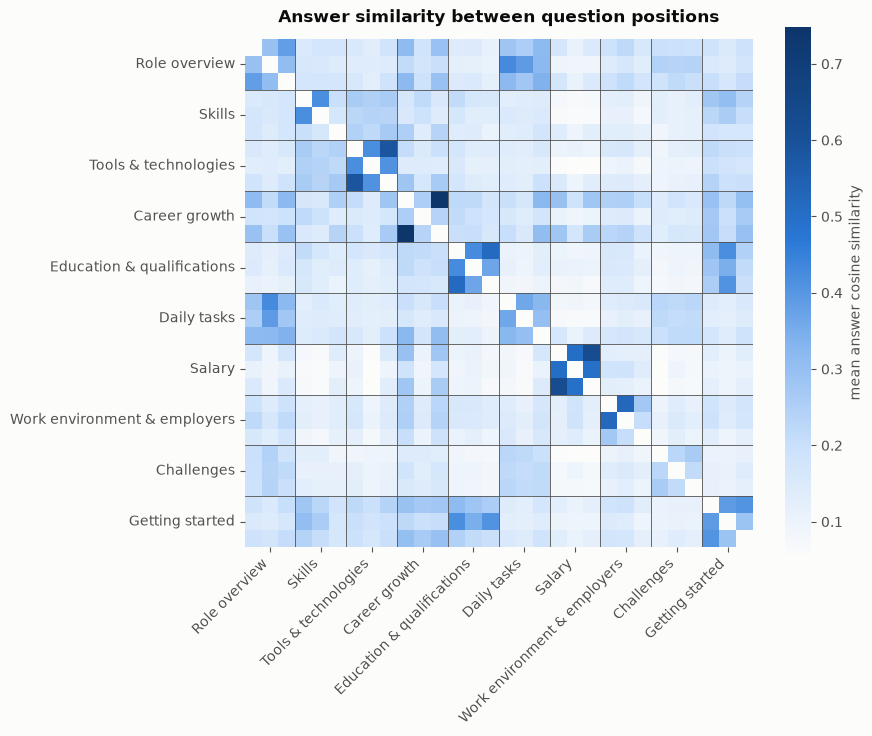

Positions whose most similar position is in the same intent block: 22 / 30


,question template,derived intent,most similar positions (by answers),nearest is in own block
position,,,,
1,What are the main responsibilities of a <ROLE>?,role_overview,"[15, 16, 17]",False
5,Which programming languages are important for a <ROLE>?,skills,"[8, 9, 6]",False
10,How do I progress in a career as a <ROLE>?,career_growth,"[27, 29, 9]",False
15,What does a typical day look like for a <ROLE>?,daily_tasks,"[1, 16, 17]",False
16,What are the daily tasks of a <ROLE>?,daily_tasks,"[1, 15, 17]",False
17,What does a <ROLE> do on a daily basis?,daily_tasks,"[2, 15, 9]",False
25,What difficulties do <ROLE> face in their jobs?,challenges,"[1, 24, 15]",False
28,What are the entry-level requirements for a <ROLE>?,getting_started,"[12, 14, 27]",False


In [8]:
pos = chk.position.to_numpy()
same_role = role_arr[:, None] == role_arr[None, :]
P = np.full((30, 30), np.nan)
for i in range(30):
    for j in range(30):
        if i != j:
            P[i, j] = S[same_role & (pos[:, None] == i) & (pos[None, :] == j)].mean()
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(P, cmap=SEQ_BLUES, square=True, cbar_kws={"label": "mean answer cosine similarity"}, ax=ax); ax.grid(False)
for b in range(3, 30, 3):
    ax.axhline(b, color=INK2, lw=0.6); ax.axvline(b, color=INK2, lw=0.6)
ax.set_xticks(np.arange(1.5, 30, 3)); ax.set_xticklabels([INTENT_NAMES[i] for i in INTENTS], rotation=45, ha="right")
ax.set_yticks(np.arange(1.5, 30, 3)); ax.set_yticklabels([INTENT_NAMES[i] for i in INTENTS], rotation=0)
ax.set_title("Answer similarity between question positions", pad=12)
plt.tight_layout(); plt.show()

nearest = pd.DataFrame({"question template": per_pos.most_common_template,
                        "derived intent": [INTENTS[p // 3] for p in range(30)],
                        "most similar positions (by answers)": [np.argsort(-np.nan_to_num(P[i], nan=-1))[:3].tolist() for i in range(30)]})
nearest["nearest is in own block"] = [r[0] // 3 == i // 3 for i, r in enumerate(nearest["most similar positions (by answers)"])]
print(f"Positions whose most similar position is in the same intent block: {nearest['nearest is in own block'].sum()} / 30")
nearest[~nearest["nearest is in own block"]]

Most positions are closest to the other members of their own intent block, so the grouping is confirmed
by the *answers* and not only by the question order. The exceptions are informative — they are questions whose
topic genuinely overlaps another intent (for example *"Which programming languages are important for …?"* has
answers that read like the **tools & technologies** answers, and *"What are the entry-level requirements …?"*
overlaps with **education**). We keep the structural 10 × 3 grouping (it follows the dataset's order and keeps the
classes balanced) but expect these ambiguous positions to cause errors; Section 15 checks this.

**Role names inside questions.** We also check how often the role's name appears in the question text
— this tells us how hard role prediction will be:

In [9]:
base_name = df.role.str.replace(r"\s*\(.*?\)", "", regex=True).str.lower()
contains = [b in q.lower() for b, q in zip(base_name, df.question)]
print(f"Questions that literally contain the role name: {np.mean(contains):.1%}")

Questions that literally contain the role name: 98.0%


## 5. Exploratory data analysis

,count,mean,std,min,25%,50%,75%,max
q_words,1620.0,9.6,1.6,6.0,9.0,10.0,10.0,16.0
a_words,1620.0,27.8,5.1,15.0,24.0,28.0,31.0,43.0


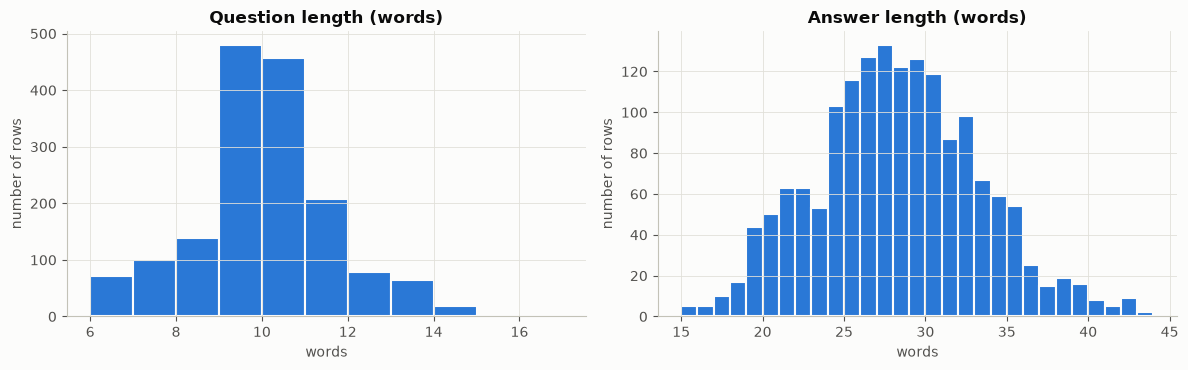

In [10]:
df["q_words"] = df.question.str.split().str.len()
df["a_words"] = df.answer.str.split().str.len()
display(df[["q_words", "a_words"]].describe().T.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col, title in [(axes[0], "q_words", "Question length"), (axes[1], "a_words", "Answer length")]:
    ax.hist(df[col], bins=range(df[col].min(), df[col].max() + 2), color=BLUE, edgecolor="#fcfcfb", linewidth=1.5)
    ax.set(title=f"{title} (words)", xlabel="words", ylabel="number of rows")
plt.tight_layout(); plt.show()

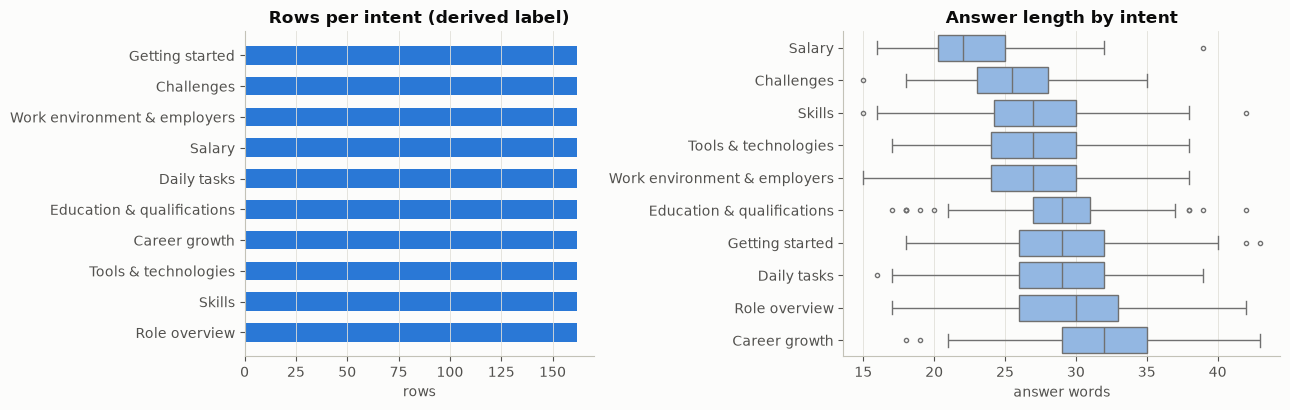

Roles are perfectly balanced: True (30 questions each)


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
ic = df.intent.map(INTENT_NAMES).value_counts().sort_values()
axes[0].barh(ic.index, ic.values, color=BLUE, height=0.6); axes[0].grid(False, axis="y")
axes[0].set(title="Rows per intent (derived label)", xlabel="rows")
order = df.groupby("intent").a_words.median().sort_values().index
sns.boxplot(data=df, y=df.intent.map(INTENT_NAMES), x="a_words", order=[INTENT_NAMES[i] for i in order],
            ax=axes[1], color="#86b6ef", linewidth=1, fliersize=3)
axes[1].set(title="Answer length by intent", xlabel="answer words", ylabel="")
plt.tight_layout(); plt.show()
print("Roles are perfectly balanced:", role_counts.nunique() == 1, f"({role_counts.iloc[0]} questions each)")

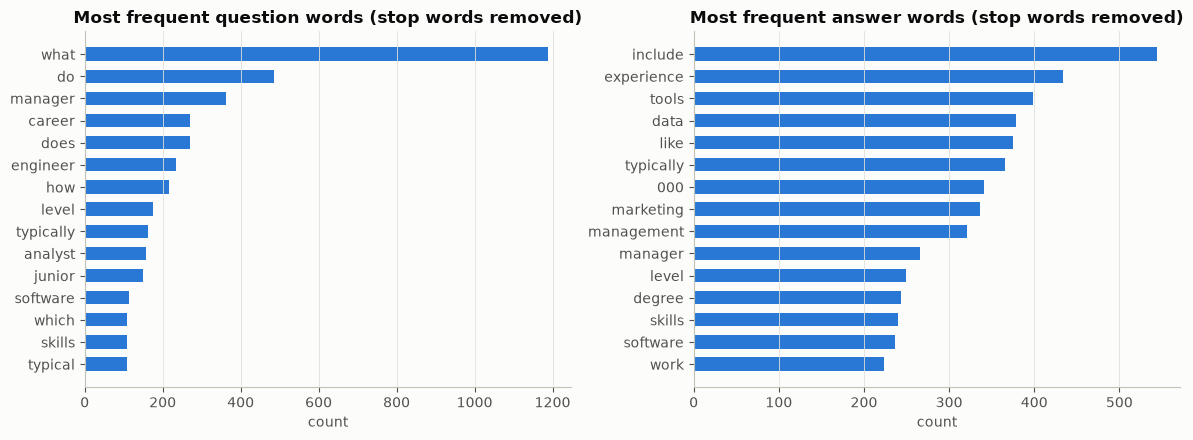

In [12]:
pre_eda = TextPreprocessor(remove_stopwords=True, stem=False)
def top_terms(texts, n=15):
    return pd.Series([t for x in texts for t in pre_eda.tokens(x)]).value_counts().head(n)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, title in [(axes[0], "question", "Most frequent question words"),
                       (axes[1], "answer", "Most frequent answer words")]:
    tt = top_terms(df[col]).sort_values()
    ax.barh(tt.index, tt.values, color=BLUE, height=0.6); ax.grid(False, axis="y")
    ax.set(title=title + " (stop words removed)", xlabel="count")
plt.tight_layout(); plt.show()

In [13]:
# Which words distinguish each intent? Top TF-IDF terms of the questions belonging to each intent.
vec_eda = TfidfVectorizer(preprocessor=pre_eda, token_pattern=r"\S+")
Xq = vec_eda.fit_transform(df.question)
terms = np.array(vec_eda.get_feature_names_out())
rows = {}
for intent in INTENTS:
    mean_w = np.asarray(Xq[(df.intent == intent).to_numpy()].mean(axis=0)).ravel()
    rows[INTENT_NAMES[intent]] = ", ".join(terms[mean_w.argsort()[::-1][:6]])
pd.Series(rows, name="top TF-IDF question terms").to_frame()

,top TF-IDF question terms
Role overview,"responsibilities, description, job, main, what, does"
Skills,"skills, required, successful, essential, important, programming"
Tools & technologies,"proficient, tools, use, software, technologies, role"
Career growth,"career, progress, trajectory, path, growth, typical"
Education & qualifications,"need, educational, qualifications, do, pursue, degree"
Daily tasks,"daily, does, tasks, basis, what, look"
Salary,"salary, range, average, much, earn, annually"
Work environment & employers,"work, environment, expect, where, hire, kind"
Challenges,"challenges, biggest, problems, encounter, difficulties, face"
Getting started,"how, start, entry, working, begin, level"


**EDA findings**
- 1,620 rows, 54 perfectly balanced roles (30 each) and 10 balanced derived intents (162 each).
- Questions are short (≈10 words) and template-based; answers are 15–43 words.
- The role name appears in almost every question, so role prediction should be easy.
- Intent is signalled by a few key words (*salary/earn*, *skills*, *tools/software*, *degree/qualifications* …).
  Each intent has only **3 wordings**, so a model must generalise to wordings it has never seen —
  this is the real NLP challenge in this dataset.

## 6. Text cleaning and NLP preprocessing

`chatbot_core.TextPreprocessor` (shared with the app) applies:
1. **Unicode normalisation** (NFKC) and **lower-casing**;
2. **Tokenisation** with a regular expression (keeps tokens like `c++`, `c#`; strips `'s` from `what's`);
3. **Stop-word removal** using scikit-learn's English list, *except* question words that carry intent
   (`how`, `much`, `where`, `what`, `which`, `why`, `when`, `do`) — e.g. *"where do … work"* signals the
   work-environment intent and *"how much"* signals salary;
4. **Stemming** with NLTK's Snowball stemmer (*earns → earn*, *developers → develop*).

The preprocessor runs *inside* the TF-IDF vectorizer, so it is saved with the model and applied
identically at training and inference time. Which combination of steps works best is decided
empirically in Section 11.

In [14]:
variants = {"lowercase + tokenise only": TextPreprocessor(False, False),
            "+ stop-word removal": TextPreprocessor(True, False),
            "+ stop-word removal + stemming": TextPreprocessor(True, True)}
examples = ["How much do Data Scientists earn annually?",
            "What's the career growth path for a Site Reliability Engineer (SRE)?",
            "Which programming languages are important for a Game Developer?"]
pd.DataFrame({name: [p(e) for e in examples] for name, p in variants.items()}, index=examples)

,lowercase + tokenise only,+ stop-word removal,+ stop-word removal + stemming
How much do Data Scientists earn annually?,how much do data scientists earn annually,how much do data scientists earn annually,how much do data scientist earn annual
What's the career growth path for a Site Reliability Engineer (SRE)?,what the career growth path for a site reliability engineer sre,what career growth path site reliability engineer sre,what career growth path site reliabl engin sre
Which programming languages are important for a Game Developer?,which programming languages are important for a game developer,which programming languages important game developer,which program languag import game develop


In [15]:
pd.DataFrame({name: {"vocabulary size (questions)": len({t for q in df.question for t in p.tokens(q)}),
                     "vocabulary size (questions + answers)": len({t for x in pd.concat([df.question, df.answer]) for t in p.tokens(x)})}
              for name, p in variants.items()}).T

,vocabulary size (questions),vocabulary size (questions + answers)
lowercase + tokenise only,187,2391
+ stop-word removal,169,2271
+ stop-word removal + stemming,141,1502


## 7. Train/test split and data-leakage prevention

A random split would be misleading here: the same question template appears for all 54 roles and the
three paraphrases of a group are near-duplicates in meaning. We therefore use a
**leave-one-paraphrase-out split**:

- **Test set:** paraphrase slot 2 of every (role, intent) group — 540 questions. Every test question uses a
  *wording that never appears in training* (for any role).
- **Training set / knowledge base:** slots 0 and 1 — 1,080 question–answer pairs. Every test question still
  has 2 sibling questions in the knowledge base, so a correct answer exists.
- **Model selection and threshold tuning** use only the training set, with an inner 2-fold split
  (train on slot 0 → validate on slot 1, and vice versa). The test set is used once, in Section 13.
- All vectorizers and classifiers are fitted only on training data (`CareerChatbot.fit` fits everything on the
  knowledge base it is given). The test answers are never used for training.
- The pretrained sentence-embedding model (MiniLM) is *not* trained on our data, so pre-computing its
  embeddings for all rows does not leak test information.

In [16]:
TEST_SLOT = 2
train_df = df[df.paraphrase_slot != TEST_SLOT].reset_index(drop=True)
test_df = df[df.paraphrase_slot == TEST_SLOT].reset_index(drop=True)
inner_folds = [(train_df[train_df.paraphrase_slot != k].reset_index(drop=True),
                train_df[train_df.paraphrase_slot == k].reset_index(drop=True)) for k in (0, 1)]

# Leakage checks
assert not set(train_df.question) & set(test_df.question), "question overlap"
assert not set(train_df.answer) & set(test_df.answer), "answer overlap"
test_templates = set(chk.loc[chk.position % 3 == TEST_SLOT, "template"])
train_templates = set(chk.loc[chk.position % 3 != TEST_SLOT, "template"])
assert (train_df.groupby(["role", "intent"]).size() == 2).all()
print(f"train/KB: {len(train_df)}  test: {len(test_df)}  inner folds: {[ (len(a), len(b)) for a, b in inner_folds ]}")
print(f"Test question templates also present in training: {len(test_templates & train_templates)} of {len(test_templates)}")

train/KB: 1080  test: 540  inner folds: [(540, 540), (540, 540)]
Test question templates also present in training: 0 of 10


## 8. Feature extraction using TF-IDF

**TF-IDF** (term frequency × inverse document frequency) represents each question as a sparse vector in
which words that are frequent in the question but rare across the corpus get high weight. We use unigrams
and bigrams (`ngram_range=(1, 2)`), sub-linear TF (`1 + log tf`) and L2-normalised rows, so the dot product
of two vectors is their **cosine similarity**.

In [17]:
vec = cc.build_vectorizer(TextPreprocessor())
X_train = vec.fit_transform(train_df.question)          # fitted on training questions only
terms = vec.get_feature_names_out()
print(f"TF-IDF matrix: {X_train.shape[0]} questions x {X_train.shape[1]} features, "
      f"density {X_train.nnz / np.prod(X_train.shape):.2%}")
idf = pd.Series(vec.idf_, index=terms)
pd.DataFrame({"lowest IDF (common)": idf.nsmallest(8).index, "highest IDF (rare)": idf.nlargest(8).index})

TF-IDF matrix: 1080 questions x 1005 features, density 1.21%


,lowest IDF (common),highest IDF (rare)
0,what,adjust do
1,do,adjust earn
2,manag,adjust face
3,career,adjust role
4,engin,advisor do
5,doe,advisor earn
6,how,advisor face
7,typic,advisor role


In [18]:
q = train_df.question[0]
row = X_train[0].toarray().ravel()
print("Question:", q)
pd.Series(row, index=terms)[row > 0].sort_values(ascending=False).round(3).to_frame("tf-idf weight")

Question: What does a Data Scientist do?


,tf-idf weight
scientist do,0.547
doe data,0.453
scientist,0.370
data scientist,0.370
data,0.290
what doe,0.247
doe,0.217
do,0.144
what,0.096


For comparison we also use **sentence embeddings** from the pretrained `all-MiniLM-L6-v2` model
(384-dimensional dense vectors). Unlike TF-IDF, embeddings place words with similar meaning
(*salary* ↔ *earn* ↔ *pay*) close together, which should help with unseen wordings. We compute them once
and cache them by text.

In [19]:
t0 = time.time()
all_texts = pd.concat([df.question, df.answer]).tolist()
EMB = dict(zip(all_texts, cc.embed(all_texts)))
emb = lambda texts: np.vstack([EMB[t] for t in texts])
print(f"Embedded {len(all_texts)} texts with {cc.EMBEDDING_MODEL} in {time.time() - t0:.1f}s; dim = {len(EMB[all_texts[0]])}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedded 3240 texts with sentence-transformers/all-MiniLM-L6-v2 in 19.2s; dim = 384


## 9. Model development: approach

The dataset is a knowledge base of question–answer pairs with two (verified) labels per question. A user
question must be mapped to the right stored answer. Two families of methods fit this structure:

| Approach | How it works | Strength | Weakness |
|---|---|---|---|
| **Retrieval** (Section 10) | Vectorise the query, return the answer of the most cosine-similar stored question | Simple, no labels needed | Matches *wording*: "How much do X earn?" may match the same template for a *different* role |
| **Classification** (Section 11) | Predict **role** (54 classes) and **intent** (10 classes) separately with Logistic Regression | Uses the label structure; learns which words signal role vs. topic | Needs labels; one combined decision |

**Chosen design — hybrid (`chatbot_core.CareerChatbot`):**
1. TF-IDF + Logistic Regression predicts the **role** (role names are lexical, so TF-IDF is ideal).
2. Logistic Regression predicts the **intent** from either TF-IDF or sentence-embedding features
   (chosen by validation in Section 11).
3. Within the predicted (role, intent) group, **cosine similarity** selects the closest stored question,
   and its answer is returned.
4. Class probabilities and the best similarity score drive **thresholds** for clarification and fallback (Section 12).

Logistic Regression is used for the deployed classifiers because it is accurate on sparse text features and
gives **class probabilities**, which the confidence thresholds need. Linear SVM and Naive Bayes are compared
as alternatives.

In [20]:
def intent_features(kind, augment, preprocessor=None):
    # Returns a function (train_part, eval_part) -> (X_train, y_train, X_eval) for the intent classifier.
    # augment=True also trains on the knowledge-base *answers* (labelled with their question's intent).
    def build(tr, ev):
        texts = pd.concat([tr.question, tr.answer]) if augment else tr.question
        y = pd.concat([tr.intent, tr.intent]) if augment else tr.intent
        if kind == "tfidf":
            v = cc.build_vectorizer(preprocessor or TextPreprocessor()).fit(texts)
            return v.transform(texts), y, v.transform(ev.question)
        return emb(texts), y, emb(ev.question)
    return build

def inner_cv(build, make_clf, target="intent"):
    # Mean validation accuracy / macro-F1 over the two inner folds (training data only).
    scores = []
    for tr, va in inner_folds:
        X_tr, y_tr, X_va = build(tr, va)
        clf = make_clf().fit(X_tr, y_tr)
        pred = clf.predict(X_va)
        ll = log_loss(va[target], clf.predict_proba(X_va), labels=clf.classes_) if hasattr(clf, "predict_proba") else np.nan
        scores.append([accuracy_score(va[target], pred), f1_score(va[target], pred, average="macro"), ll])
    return dict(zip(["val_accuracy", "val_macro_f1", "val_log_loss"], np.mean(scores, axis=0)))

## 10. Question–answer retrieval using cosine similarity

**Retrieval baseline:** index the knowledge-base questions, and for each query rank all stored questions by
cosine similarity. A retrieved question is **relevant** if it belongs to the same (role, intent) group as the
query (its answer is then a correct response).

**Retrieval metrics**
- **Hit@k** — share of queries with at least one relevant question in the top *k* (Hit@1 = top-1 accuracy).
- **MRR** (mean reciprocal rank) — average of 1 / rank of the first relevant result; rewards ranking the right
  answer high even when it is not first.

In [21]:
def retrieval_metrics(sims, kb, queries, ks=(1, 3, 5)):
    rel = ((kb.role.to_numpy()[None, :] == queries.role.to_numpy()[:, None]) &
           (kb.intent.to_numpy()[None, :] == queries.intent.to_numpy()[:, None]))
    order = np.argsort(-sims, axis=1)
    first = np.take_along_axis(rel, order, axis=1).argmax(axis=1)   # rank (0-based) of first relevant hit
    out = {f"Hit@{k}": (first < k).mean() for k in ks}
    out["MRR"] = (1.0 / (first + 1)).mean()
    return out

def tfidf_sims(kb, queries, preprocessor=None):
    v = cc.build_vectorizer(preprocessor or TextPreprocessor()).fit(kb.question)
    return (v.transform(queries.question) @ v.transform(kb.question).T).toarray()

def emb_sims(kb, queries):
    return emb(queries.question) @ emb(kb.question).T

ret_val = {}
for name, fn in [("TF-IDF cosine retrieval", tfidf_sims), ("MiniLM embedding cosine retrieval", emb_sims)]:
    ret_val[name] = pd.DataFrame([retrieval_metrics(fn(tr, va), tr, va) for tr, va in inner_folds]).mean()
pd.DataFrame(ret_val).T.round(3)

,Hit@1,Hit@3,Hit@5,MRR
TF-IDF cosine retrieval,0.261,0.491,0.598,0.442
MiniLM embedding cosine retrieval,0.763,0.951,0.998,0.860


In [22]:
# What does retrieval return? Top-3 neighbours for one validation query (fold: train on slot 0, validate on slot 1)
tr, va = inner_folds[1]
qi = va.index[(va.role == "Data Analyst") & (va.intent == "salary")][0]
for name, fn in [("TF-IDF", tfidf_sims), ("MiniLM", emb_sims)]:
    s = fn(tr, va.loc[[qi]])[0]
    top = np.argsort(-s)[:3]
    print(f"\n[{name}] query: {va.question[qi]!r}")
    for j in top:
        ok = "✓" if (tr.role[j], tr.intent[j]) == (va.role[qi], va.intent[qi]) else "✗"
        print(f"   {ok} {s[j]:.3f}  {tr.question[j]}  ({tr.role[j]} / {tr.intent[j]})")


[TF-IDF] query: 'How much do Data Analysts earn annually?'
   ✗ 0.702  Where do Data Analysts typically work?  (Data Analyst / work_environment)
   ✗ 0.525  How do I start a career as a Data Analyst?  (Data Analyst / getting_started)
   ✗ 0.479  What does a Data Analyst do?  (Data Analyst / role_overview)

[MiniLM] query: 'How much do Data Analysts earn annually?'
   ✓ 0.865  What is the average salary for a Data Analyst?  (Data Analyst / salary)
   ✗ 0.769  What is the average salary for a Data Scientist?  (Data Scientist / salary)
   ✗ 0.765  Where do Data Analysts typically work?  (Data Analyst / work_environment)


Pure retrieval often matches the **template** rather than the meaning: a salary question can retrieve the
identical wording for another role. This motivates predicting role and intent separately (Section 11).

## 11. Classification models

### 11.1 Role classifier (54 classes)

In [23]:
role_build = lambda tr, va: (lambda v: (v.transform(tr.question), tr.role, v.transform(va.question)))(
    cc.build_vectorizer(TextPreprocessor()).fit(tr.question))
role_results = {
    "TF-IDF + Logistic Regression": inner_cv(role_build, lambda: LogisticRegression(C=10, max_iter=5000), "role"),
    "TF-IDF + Linear SVM": inner_cv(role_build, lambda: LinearSVC(C=1), "role"),
    "TF-IDF + Complement NB": inner_cv(role_build, lambda: ComplementNB(alpha=0.3), "role"),
}
pd.DataFrame(role_results).T.round(3)

,val_accuracy,val_macro_f1,val_log_loss
TF-IDF + Logistic Regression,1.0,1.0,0.041
TF-IDF + Linear SVM,1.0,1.0,NaN
TF-IDF + Complement NB,1.0,1.0,1.176


As expected from Section 4, role prediction is easy because the role name is in the question; all
models are close to perfect. Logistic Regression is kept for its probabilities.

### 11.2 Intent classifier (10 classes) — feature and model comparison

The intent must be recognised from a **wording not seen in training**. We compare feature sets
(TF-IDF vs. MiniLM embeddings, with or without the knowledge-base answers as extra training text) and
classifiers, using inner validation only.

In [24]:
t0 = time.time()
candidates = []
for feat in ["tfidf", "embedding"]:
    for augment in [False, True]:
        build = intent_features(feat, augment)
        clfs = {"Logistic Regression": lambda: LogisticRegression(C=10, max_iter=5000),
                "Linear SVM": lambda: LinearSVC(C=1)}
        if feat == "tfidf":
            clfs["Complement NB"] = lambda: ComplementNB(alpha=0.3)
        for clf_name, make in clfs.items():
            candidates.append({"features": feat, "train on answers too": augment, "classifier": clf_name,
                               **inner_cv(build, make)})
intent_cmp = pd.DataFrame(candidates).sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
print(f"({time.time() - t0:.1f}s)")
intent_cmp.round(3)

(4.3s)


,features,train on answers too,classifier,val_accuracy,val_macro_f1,val_log_loss
0,embedding,False,Linear SVM,0.799,0.766,NaN
1,embedding,True,Linear SVM,0.794,0.760,NaN
2,embedding,False,Logistic Regression,0.781,0.749,0.928
3,embedding,True,Logistic Regression,0.776,0.740,0.812
4,tfidf,True,Linear SVM,0.583,0.493,NaN
5,tfidf,True,Logistic Regression,0.542,0.452,1.697
6,tfidf,True,Complement NB,0.502,0.399,1.850
7,tfidf,False,Linear SVM,0.400,0.312,NaN
8,tfidf,False,Logistic Regression,0.396,0.308,2.090
9,tfidf,False,Complement NB,0.377,0.306,2.047


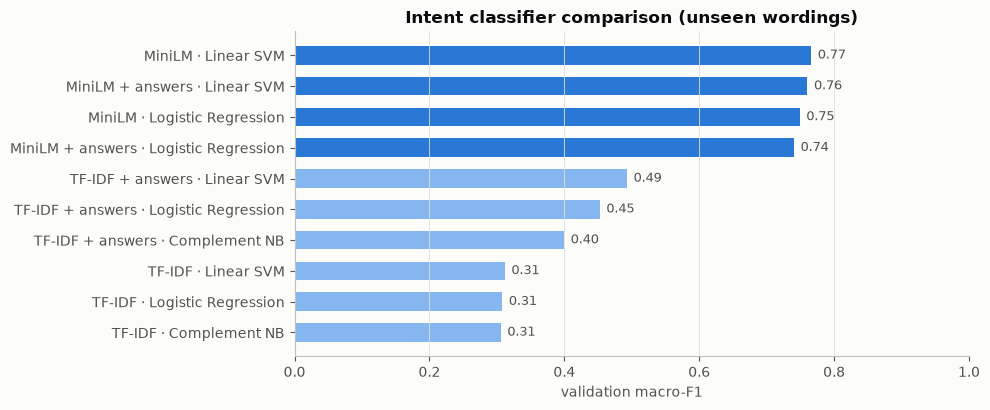

In [25]:
fig, ax = plt.subplots(figsize=(10, 4.2))
lbl = intent_cmp.apply(lambda r: f"{'MiniLM' if r.features == 'embedding' else 'TF-IDF'}"
                                 f"{' + answers' if r['train on answers too'] else ''} · {r.classifier}", axis=1)
plot = intent_cmp.assign(label=lbl).sort_values("val_macro_f1")
colors = [BLUE if f == "embedding" else "#86b6ef" for f in plot.features]
ax.barh(plot.label, plot.val_macro_f1, color=colors, height=0.6); ax.grid(False, axis="y")
for y, v in enumerate(plot.val_macro_f1):
    ax.text(v + 0.01, y, f"{v:.2f}", va="center", color=INK2, fontsize=9)
ax.set(xlim=(0, 1), xlabel="validation macro-F1", title="Intent classifier comparison (unseen wordings)")
plt.tight_layout(); plt.show()

**Preprocessing ablation** (TF-IDF + answers + Logistic Regression) and **regularisation strength** for the best Logistic Regression feature set:

In [26]:
ablation = pd.DataFrame({name: inner_cv(intent_features("tfidf", True, p), lambda: LogisticRegression(C=10, max_iter=5000))
                         for name, p in variants.items()}).T
display(ablation.round(3))
BEST_PRE_NAME = ablation.val_macro_f1.idxmax()
BEST_PRE = variants[BEST_PRE_NAME]

best_lr = intent_cmp[intent_cmp.classifier == "Logistic Regression"].iloc[0]
c_grid = pd.DataFrame({C: inner_cv(intent_features(best_lr.features, bool(best_lr["train on answers too"]), BEST_PRE),
                                   lambda C=C: LogisticRegression(C=C, max_iter=5000))
                       for C in [0.1, 1, 10, 100]}).T.rename_axis("C")
display(c_grid.round(3))

BEST_CONFIG = dict(intent_features=best_lr.features, augment_with_answers=bool(best_lr["train on answers too"]),
                   intent_C=float(c_grid.val_log_loss.idxmin()), role_C=10.0, preprocessor=BEST_PRE)
print("Selected configuration:", {k: v for k, v in BEST_CONFIG.items()})

,val_accuracy,val_macro_f1,val_log_loss
lowercase + tokenise only,0.337,0.265,2.109
+ stop-word removal,0.565,0.472,1.725
+ stop-word removal + stemming,0.542,0.452,1.697


,val_accuracy,val_macro_f1,val_log_loss
C,,,
0.1,0.792,0.766,1.814
1.0,0.781,0.752,1.167
10.0,0.781,0.749,0.928
100.0,0.781,0.749,0.897


Selected configuration: {'intent_features': 'embedding', 'augment_with_answers': False, 'intent_C': 100.0, 'role_C': 10.0, 'preprocessor': TextPreprocessor(remove_stopwords=True, stem=False)}


The selection is made programmatically from validation scores (no test data involved):
- **feature set:** the Logistic Regression candidate with the best validation macro-F1;
- **preprocessing:** the variant with the best macro-F1 (only affects TF-IDF features — the role classifier and TF-IDF retrieval);
- **regularisation `C`:** the lowest validation **log-loss**. Macro-F1 barely changes with `C`, but strong regularisation
  produces flat, under-confident probabilities. Because the probabilities drive the thresholds (Section 12) and the
  confidence shown in the app, probability quality (log-loss, a proper scoring rule) is the right criterion here.

Logistic Regression is used for the deployed model even if Linear SVM scores slightly higher, because the
thresholds need class probabilities.

## 12. Response selection, confidence thresholds and fallback responses

For each query the chatbot computes three signals and applies one policy
(`CareerChatbot.decide`, used by both this notebook and the app):

| Signal | Meaning |
|---|---|
| `max_similarity` | cosine similarity of the query to the closest stored question (any group) |
| `role_conf` | probability of the predicted role |
| `intent_conf` | probability of the predicted intent |

| Condition | Response |
|---|---|
| `max_similarity < min_similarity`, or both confidences low | **fallback** — out of scope, explain what the bot can do |
| role confidence low, intent confident | **clarify_role** — "which career do you mean?" |
| intent confidence low, role confident | **clarify_intent** — list the topics the bot knows |
| otherwise | **answer** — the closest stored question within the predicted (role, intent) group |

**Calibration data (training side only).** The thresholds are learned from
(a) out-of-fold predictions on the training questions (inner folds) — in-domain questions;
(b) small hand-written sets of **out-of-domain** questions and **role-free** career questions, written for this
project and labelled as such. Separate hand-written sets are kept aside for testing in Section 13.

In [27]:
# Hand-written query sets (NOT from the dataset). Calibration and test sets are disjoint.
OOD_CALIB = ["what's the weather like today", "tell me a joke", "who won the football match yesterday",
             "how do i cook pasta", "what is the capital of france", "recommend a good movie",
             "how tall is mount everest", "play some music", "what time is it", "translate hello into spanish",
             "my laptop won't turn on", "best pizza place near me", "how do plants grow", "what is 2 plus 2",
             "write a poem about the sea"]
OOD_TEST = ["how do i fix a flat tire", "who is the president of the united states", "what's a good recipe for cookies",
            "how far is the moon", "can you book me a flight", "what is the meaning of life", "how to lose weight fast",
            "which phone should i buy", "tell me about the history of rome", "how do i train my dog",
            "is it going to rain tomorrow", "what is quantum physics", "how many legs does a spider have",
            "sing me a song", "what's the score of the game"]
ROLEFREE_CALIB = ["what is the average salary?", "how do i start my career?", "what skills do i need?",
                  "what tools should i learn?", "what does a typical workday look like?", "do i need a degree?"]
ROLEFREE_TEST = ["how much can i earn?", "what are the biggest challenges in this job?", "what qualifications are required?",
                 "how can i grow in my career?", "where would i work?", "what are the main responsibilities?"]

cal_in, cal_ood, cal_rf = [], [], []
for tr, va in inner_folds:
    bot = CareerChatbot(**BEST_CONFIG).fit(tr)
    p = bot.predict(va.question)
    p["correct"] = (p.pred_role.to_numpy() == va.role.to_numpy()) & (p.pred_intent.to_numpy() == va.intent.to_numpy())
    cal_in.append(p); cal_ood.append(bot.predict(OOD_CALIB)); cal_rf.append(bot.predict(ROLEFREE_CALIB))
cal_in, cal_ood, cal_rf = (pd.concat(x, ignore_index=True) for x in (cal_in, cal_ood, cal_rf))
pd.DataFrame({name: d[["max_similarity", "role_conf", "intent_conf"]].median()
              for name, d in [("in-domain (OOF)", cal_in), ("role-free", cal_rf), ("out-of-domain", cal_ood)]}).T.round(3)

,max_similarity,role_conf,intent_conf
in-domain (OOF),0.864,0.973,0.834
role-free,0.652,0.023,0.997
out-of-domain,0.173,0.022,0.480


In [28]:
GRID_T = np.linspace(0, 1, 1001)

def separating_threshold(pos, neg):
    # Threshold maximising balanced accuracy (pos kept, neg rejected); ties -> middle of the best range.
    bal = np.array([((pos >= t).mean() + (neg < t).mean()) / 2 for t in GRID_T])
    best = GRID_T[bal >= bal.max() - 1e-12]
    return float(np.median(best)), float(bal.max())

def utility_threshold(conf, correct):
    # Answer only when it pays off: +1 per correct answer, -1 per wrong answer, 0 when asking to clarify.
    util = np.array([(correct & (conf >= t)).sum() - (~correct & (conf >= t)).sum() for t in GRID_T])
    best = GRID_T[util == util.max()]
    return float(np.median(best)), int(util.max())

t_sim, bal_sim = separating_threshold(np.r_[cal_in.max_similarity, cal_rf.max_similarity], cal_ood.max_similarity.to_numpy())
t_role, bal_role = separating_threshold(cal_in.role_conf.to_numpy(), np.r_[cal_rf.role_conf, cal_ood.role_conf])
t_int, util_int = utility_threshold(cal_in.intent_conf.to_numpy(), cal_in.correct.to_numpy())
THRESHOLDS = Thresholds(min_similarity=round(t_sim, 3), min_role_conf=round(t_role, 3), min_intent_conf=round(t_int, 3))
print(f"min_similarity  = {THRESHOLDS.min_similarity}  (balanced accuracy in-scope vs out-of-domain: {bal_sim:.3f})")
print(f"min_role_conf   = {THRESHOLDS.min_role_conf}  (balanced accuracy role-named vs role-free/OOD: {bal_role:.3f})")
print(f"min_intent_conf = {THRESHOLDS.min_intent_conf}  (max utility on {len(cal_in)} OOF questions: {util_int})")

min_similarity  = 0.441  (balanced accuracy in-scope vs out-of-domain: 1.000)
min_role_conf   = 0.276  (balanced accuracy role-named vs role-free/OOD: 1.000)
min_intent_conf = 0.319  (max utility on 1080 OOF questions: 607)


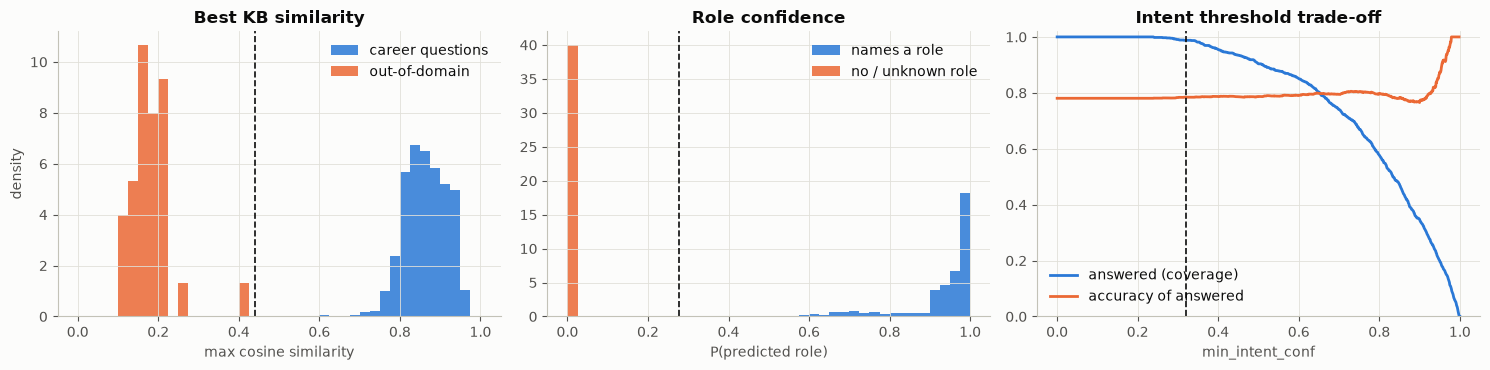

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
ax = axes[0]
bins = np.linspace(0, 1, 41)
ax.hist(np.r_[cal_in.max_similarity, cal_rf.max_similarity], bins=bins, color=BLUE, alpha=0.85, density=True, label="career questions")
ax.hist(cal_ood.max_similarity, bins=bins, color=ORANGE, alpha=0.85, density=True, label="out-of-domain")
ax.axvline(THRESHOLDS.min_similarity, color=INK, ls="--", lw=1.2)
ax.set(title="Best KB similarity", xlabel="max cosine similarity", ylabel="density"); ax.legend(frameon=False)

ax = axes[1]
ax.hist(cal_in.role_conf, bins=bins, color=BLUE, alpha=0.85, density=True, label="names a role")
ax.hist(np.r_[cal_rf.role_conf, cal_ood.role_conf], bins=bins, color=ORANGE, alpha=0.85, density=True, label="no / unknown role")
ax.axvline(THRESHOLDS.min_role_conf, color=INK, ls="--", lw=1.2)
ax.set(title="Role confidence", xlabel="P(predicted role)"); ax.legend(frameon=False)

ax = axes[2]
conf, corr = cal_in.intent_conf.to_numpy(), cal_in.correct.to_numpy()
coverage = [(conf >= t).mean() for t in GRID_T]
sel_acc = [corr[conf >= t].mean() if (conf >= t).any() else np.nan for t in GRID_T]
ax.plot(GRID_T, coverage, color=BLUE, lw=2, label="answered (coverage)")
ax.plot(GRID_T, sel_acc, color=ORANGE, lw=2, label="accuracy of answered")
ax.axvline(THRESHOLDS.min_intent_conf, color=INK, ls="--", lw=1.2)
ax.set(title="Intent threshold trade-off", xlabel="min_intent_conf", ylim=(0, 1.02)); ax.legend(frameon=False, loc="lower left")
plt.tight_layout(); plt.show()

Raising the intent threshold makes the bot answer fewer questions but be right more often; the dashed
line is the point that maximises *correct − wrong* answers. Dashed lines on the other two panels are the
data-driven out-of-scope and missing-role thresholds.

## 13. Model evaluation on the held-out test set

The selected configuration and thresholds are now fitted on the full training set (slots 0–1) and evaluated
**once** on the test set (slot 2: 540 questions with unseen wordings).

**Metrics used and why**
- **Classification (role, intent):** accuracy; **macro** precision, recall and F1 (every class counts equally —
  the classes are balanced, but macro averages expose weak classes); confusion matrix.
- **Retrieval:** Hit@k and MRR (Section 10).
- **Full chatbot (with thresholds):** *coverage* (share answered), *accuracy of answered* (selective accuracy),
  *wrong-answer rate*, plus the fallback rate on out-of-domain questions and the clarification rate on role-free questions.

In [30]:
eval_bot = CareerChatbot(**BEST_CONFIG, thresholds=THRESHOLDS).fit(train_df)
pt = eval_bot.predict(test_df.question)
pt["decision"] = [eval_bot.decide(r, i, s) for r, i, s in zip(pt.role_conf, pt.intent_conf, pt.max_similarity)]
y_role, y_int = test_df.role.to_numpy(), test_df.intent.to_numpy()
pt["role_ok"], pt["intent_ok"] = pt.pred_role.to_numpy() == y_role, pt.pred_intent.to_numpy() == y_int
pt["correct"] = pt.role_ok & pt.intent_ok

def cls_metrics(y, pred):
    p, r, f, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y, pred), "macro_precision": p, "macro_recall": r, "macro_f1": f}

cls_table = pd.DataFrame({"Role classifier (54 classes)": cls_metrics(y_role, pt.pred_role),
                          "Intent classifier (10 classes)": cls_metrics(y_int, pt.pred_intent)}).T
cls_table.round(3)

,accuracy,macro_precision,macro_recall,macro_f1
Role classifier (54 classes),1.000,1.000,1.000,1.000
Intent classifier (10 classes),0.715,0.788,0.715,0.646


In [31]:
print(classification_report(y_int, pt.pred_intent, labels=INTENTS, target_names=[INTENT_NAMES[i] for i in INTENTS], digits=3))

                              precision    recall  f1-score   support

               Role overview      0.857     1.000     0.923        54
                      Skills      0.571     0.074     0.131        54
        Tools & technologies      0.510     0.963     0.667        54
               Career growth      1.000     1.000     1.000        54
  Education & qualifications      1.000     0.222     0.364        54
                 Daily tasks      0.789     0.833     0.811        54
                      Salary      1.000     1.000     1.000        54
Work environment & employers      1.000     0.056     0.105        54
                  Challenges      0.587     1.000     0.740        54
             Getting started      0.562     1.000     0.720        54

                    accuracy                          0.715       540
                   macro avg      0.788     0.715     0.646       540
                weighted avg      0.788     0.715     0.646       540



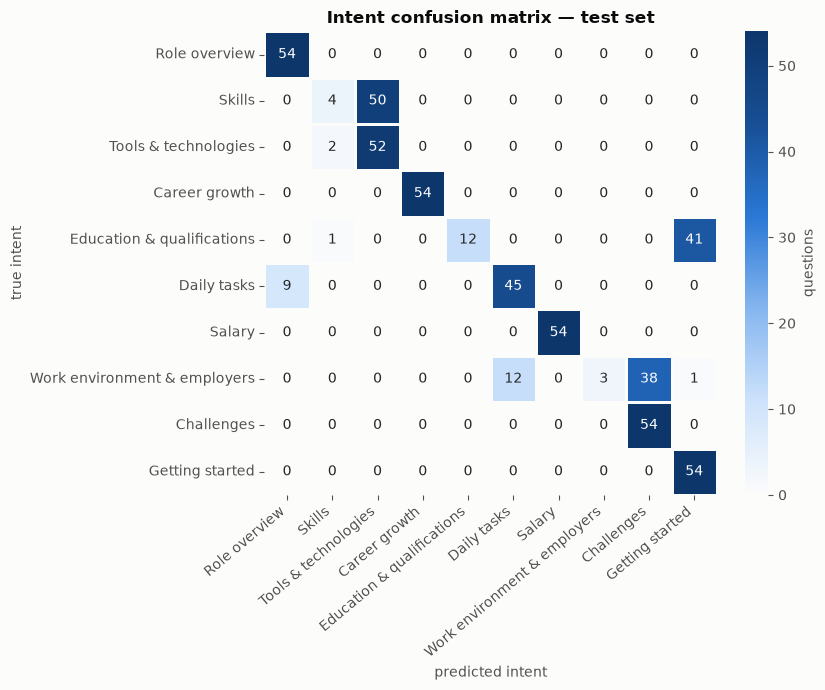

Role confusions on the test set: none


In [32]:
cm = confusion_matrix(y_int, pt.pred_intent, labels=INTENTS)
names = [INTENT_NAMES[i] for i in INTENTS]
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap=SEQ_BLUES, xticklabels=names, yticklabels=names, cbar_kws={"label": "questions"},
            linewidths=1, linecolor="#fcfcfb", ax=ax); ax.grid(False)
ax.set(title="Intent confusion matrix — test set", xlabel="predicted intent", ylabel="true intent")
plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()

role_cm = pd.crosstab(pt.pred_role, y_role)
off = [(t, p, n) for t in role_cm.columns for p, n in role_cm[t].items() if p != t and n > 0]
print("Role confusions on the test set:", off if off else "none")

In [33]:
# End-to-end comparison: which approach finds an answer from the right (role, intent) group?
rows = {}
for name, sims in [("Retrieval only: TF-IDF cosine", tfidf_sims(train_df, test_df, BEST_PRE)),
                   ("Retrieval only: MiniLM cosine", emb_sims(train_df, test_df))]:
    rows[name] = retrieval_metrics(sims, train_df, test_df)
rows["Hybrid: role clf + intent clf + cosine (no thresholds)"] = {"Hit@1": pt.correct.mean()}
e2e = pd.DataFrame(rows).T
e2e.round(3)

,Hit@1,Hit@3,Hit@5,MRR
Retrieval only: TF-IDF cosine,0.293,0.552,0.633,0.462
Retrieval only: MiniLM cosine,0.700,0.952,0.985,0.816
Hybrid: role clf + intent clf + cosine (no thresholds),0.715,NaN,NaN,NaN


In [34]:
ans = pt.decision == "answer"
system = {
    "coverage (answered)": ans.mean(),
    "accuracy of answered": pt.correct[ans].mean(),
    "wrong-answer rate (of all)": (ans & ~pt.correct).mean(),
    "asked to clarify topic": (pt.decision == "clarify_intent").mean(),
    "asked to clarify role": (pt.decision == "clarify_role").mean(),
    "fallback": (pt.decision == "fallback").mean(),
}
def decisions(queries):
    p = eval_bot.predict(queries)
    return pd.Series([eval_bot.decide(r, i, s) for r, i, s in zip(p.role_conf, p.intent_conf, p.max_similarity)])
ood_dec, rf_dec = decisions(OOD_TEST), decisions(ROLEFREE_TEST)
system["OOD test: fallback rate"] = (ood_dec == "fallback").mean()
system["role-free test: clarify-role rate"] = (rf_dec == "clarify_role").mean()
system_table = pd.Series(system, name="value").to_frame()
display(system_table.round(3))
print("OOD test decisions:", ood_dec.value_counts().to_dict(), "| role-free test decisions:", rf_dec.value_counts().to_dict())

,value
coverage (answered),0.987
accuracy of answered,0.720
wrong-answer rate (of all),0.276
asked to clarify topic,0.013
asked to clarify role,0.000
fallback,0.000
OOD test: fallback rate,1.000
role-free test: clarify-role rate,1.000


OOD test decisions: {'fallback': 15} | role-free test decisions: {'clarify_role': 6}


**Robustness check — 3-fold leave-one-paraphrase-out cross-validation.** The single test split uses one
particular wording per intent. Rotating which paraphrase slot is held out gives a less wording-dependent
estimate (the configuration chosen above is kept fixed; this is a supplementary estimate).

In [35]:
cv_rows = []
for k in range(3):
    tr, te = df[df.paraphrase_slot != k].reset_index(drop=True), df[df.paraphrase_slot == k].reset_index(drop=True)
    b = CareerChatbot(**BEST_CONFIG, thresholds=THRESHOLDS).fit(tr)
    p = b.predict(te.question)
    joint = (p.pred_role.to_numpy() == te.role.to_numpy()) & (p.pred_intent.to_numpy() == te.intent.to_numpy())
    cv_rows.append({"held-out slot": k,
                    "role accuracy": accuracy_score(te.role, p.pred_role),
                    "intent accuracy": accuracy_score(te.intent, p.pred_intent),
                    "intent macro-F1": f1_score(te.intent, p.pred_intent, average="macro"),
                    "hybrid Hit@1": joint.mean(),
                    "TF-IDF retrieval Hit@1": retrieval_metrics(tfidf_sims(tr, te, BEST_PRE), tr, te)["Hit@1"],
                    "MiniLM retrieval Hit@1": retrieval_metrics(emb_sims(tr, te), tr, te)["Hit@1"]})
cv = pd.DataFrame(cv_rows).set_index("held-out slot")
display(cv.round(3))
cv.agg(["mean", "std"]).round(3)

,role accuracy,intent accuracy,intent macro-F1,hybrid Hit@1,TF-IDF retrieval Hit@1,MiniLM retrieval Hit@1
held-out slot,,,,,,
0,1.0,0.985,0.985,0.985,0.481,0.887
1,1.0,0.787,0.754,0.787,0.374,0.796
2,1.0,0.715,0.646,0.715,0.293,0.700


,role accuracy,intent accuracy,intent macro-F1,hybrid Hit@1,TF-IDF retrieval Hit@1,MiniLM retrieval Hit@1
mean,1.0,0.829,0.795,0.829,0.383,0.794
std,0.0,0.140,0.173,0.140,0.095,0.094


### 13.1 Retrain on the full dataset and save the model

For deployment, the knowledge base should contain **all** 1,620 answers, so the final model is refitted on
the full dataset with the configuration and thresholds selected above. The test-set metrics stored in the
metadata are the ones measured above (on the model trained without the test slot).

In [36]:
final_bot = CareerChatbot(**BEST_CONFIG, thresholds=THRESHOLDS).fit(df)
final_bot.save(cc.MODEL_PATH, metadata={
    "test_metrics": {"role_accuracy": float(cls_table.loc["Role classifier (54 classes)", "accuracy"]),
                     "intent_accuracy": float(cls_table.loc["Intent classifier (10 classes)", "accuracy"]),
                     "intent_macro_f1": float(cls_table.loc["Intent classifier (10 classes)", "macro_f1"]),
                     "hybrid_hit_at_1": float(pt.correct.mean()),
                     "coverage": float(system["coverage (answered)"]),
                     "accuracy_of_answered": float(system["accuracy of answered"])},
    "cv_mean": {k: float(v) for k, v in cv.mean().items()},
    "preprocessing": repr(BEST_PRE),
})
reloaded = CareerChatbot.load(cc.MODEL_PATH)
check_q = test_df.question.head(20)
pd.testing.assert_frame_equal(reloaded.predict(check_q), final_bot.predict(check_q), check_exact=False)  # reload sanity check
print("Saved:", cc.MODEL_PATH.relative_to(Path.cwd()) if cc.MODEL_PATH.is_relative_to(Path.cwd()) else cc.MODEL_PATH,
      f"({cc.MODEL_PATH.stat().st_size / 1e6:.1f} MB)")
print(cc.METADATA_PATH.read_text())

Saved: models\career_chatbot.joblib (4.0 MB)
{
  "sklearn_version": "1.9.1",
  "dataset": "Pradeep016/career-guidance-qa-dataset",
  "embedding_model": "sentence-transformers/all-MiniLM-L6-v2",
  "intent_features": "embedding",
  "augment_with_answers": false,
  "kb_size": 1620,
  "n_roles": 54,
  "role_C": 10.0,
  "intent_C": 100.0,
  "ngram_range": [
    1,
    2
  ],
  "thresholds": {
    "min_similarity": 0.441,
    "min_role_conf": 0.276,
    "min_intent_conf": 0.319
  },
  "test_metrics": {
    "role_accuracy": 1.0,
    "intent_accuracy": 0.7148148148148148,
    "intent_macro_f1": 0.6460327490466369,
    "hybrid_hit_at_1": 0.7148148148148148,
    "coverage": 0.987037037037037,
    "accuracy_of_answered": 0.7204502814258912
  },
  "cv_mean": {
    "role accuracy": 1.0,
    "intent accuracy": 0.8290123456790123,
    "intent macro-F1": 0.7949505058699285,
    "hybrid Hit@1": 0.8290123456790123,
    "TF-IDF retrieval Hit@1": 0.38271604938271603,
    "MiniLM retrieval Hit@1": 0.794444

## 14. Sample chatbot conversations

These use the **reloaded saved model** through `respond()` — exactly what the Streamlit app calls. The
queries are written for this demo (not from the dataset) and include paraphrases, a role-free question,
an out-of-domain question and invalid input.

In [37]:
def chat(query, bot=reloaded):
    r = bot.respond(query)
    tag = f"[{r.kind}"
    if r.kind != "invalid":
        tag += f" | role {r.role} ({r.role_conf:.2f}) | intent {r.intent} ({r.intent_conf:.2f}) | sim {r.similarity:.2f}"
    print(f"You: {query!r}\nBot {tag}]\n     {r.text}")
    if r.matched_question:
        print(f"     (matched stored question: {r.matched_question!r})")
    print()

for q in ["How much money can a data scientist make?",
          "what should I study to become a web developer",
          "Which tools do QA engineers use?",
          "How do I get into SEO?",
          "what does a UX researcher do all day",
          "What is the average salary?",
          "Tell me about the Legal Assistant role",
          "What's the weather like today?",
          "   "]:
    chat(q)

You: 'How much money can a data scientist make?'
Bot [answer | role Data Scientist (0.99) | intent salary (1.00) | sim 0.90]
     Entry-level Data Scientists earn between $70,000 to $100,000 annually, while experienced professionals can earn over $150,000.
     (matched stored question: 'How much do Data Scientists earn annually?')

You: 'what should I study to become a web developer'
Bot [answer | role Web Developer (1.00) | intent education (0.54) | sim 0.84]
     Qualifications typically include a Bachelor's degree in Computer Science or related fields, although many developers enter the field through self-learning and coding boot camps.
     (matched stored question: 'What qualifications do I need to become a Web Developer?')

You: 'Which tools do QA engineers use?'
Bot [answer | role QA Engineer (0.92) | intent tools_technologies (1.00) | sim 0.97]
     QA Engineers commonly use tools like Selenium, TestNG, JUnit, Jira, QTP, LoadRunner, and Postman for manual and automated testing

## 15. Error analysis, limitations and possible improvements

### 15.1 Which intents are confused on the test set?

errors
true                         predicted                   
Skills                       Tools & technologies      50
Education & qualifications   Getting started           41
Work environment & employers Challenges                38
                             Daily tasks               12
Daily tasks                  Role overview              9
Tools & technologies         Skills                     2
Education & qualifications   Skills                     1
Work environment & employers Getting started            1

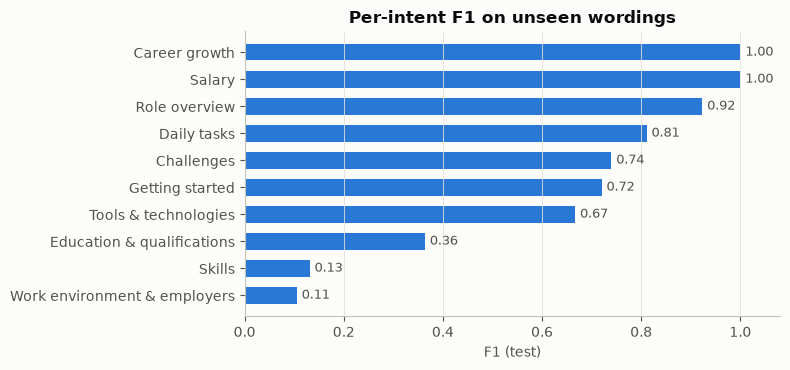

In [38]:
err = test_df.assign(pred_intent=pt.pred_intent, intent_conf=pt.intent_conf)[~pt.intent_ok.to_numpy()]
pairs = (err.assign(true=err.intent.map(INTENT_NAMES), predicted=err.pred_intent.map(INTENT_NAMES))
            .groupby(["true", "predicted"]).size().sort_values(ascending=False).rename("errors").head(8))
display(pairs.to_frame())

per_intent = pd.Series(f1_score(y_int, pt.pred_intent, labels=INTENTS, average=None), index=names).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(per_intent.index, per_intent.values, color=BLUE, height=0.6); ax.grid(False, axis="y")
for y, v in enumerate(per_intent.values):
    ax.text(v + 0.01, y, f"{v:.2f}", va="center", color=INK2, fontsize=9)
ax.set(xlim=(0, 1.08), xlabel="F1 (test)", title="Per-intent F1 on unseen wordings")
plt.tight_layout(); plt.show()

In [39]:
# Why? Compare the training wordings with the unseen test wording for the weakest intents.
for intent_name in per_intent.index[:3]:
    intent = next(k for k, v in INTENT_NAMES.items() if v == intent_name)
    tpl = chk.assign(intent=[INTENTS[p // 3] for p in chk.position])
    tpl = tpl[tpl.intent == intent].groupby(chk.position % 3).template.agg(lambda s: s.value_counts().index[0])
    wrong = err[err.intent == intent].pred_intent.map(INTENT_NAMES).value_counts().head(2).to_dict()
    print(f"{intent_name}: train wordings = {tpl[0]!r}, {tpl[1]!r}\n   test wording = {tpl[2]!r}\n   most common wrong predictions: {wrong}\n")

Work environment & employers: train wordings = 'Where do <ROLE> typically work?', 'What kind of companies hire <ROLE>?'
   test wording = 'What work environment can a <ROLE> expect?'
   most common wrong predictions: {'Challenges': 38, 'Daily tasks': 12}

Skills: train wordings = 'What skills are required to become a <ROLE>?', 'What are the essential skills for a successful <ROLE>?'
   test wording = 'Which programming languages are important for a <ROLE>?'
   most common wrong predictions: {'Tools & technologies': 50}

Education & qualifications: train wordings = 'What qualifications do I need to become a <ROLE>?', 'Do I need a degree to pursue a career as a <ROLE>?'
   test wording = 'What are the educational requirements for a <ROLE>?'
   most common wrong predictions: {'Getting started': 41, 'Skills': 1}



In [40]:
err[["role", "question", "intent", "pred_intent", "intent_conf"]].sample(min(10, len(err)), random_state=SEED)

,role,question,intent,pred_intent,intent_conf
64,Product Manager (Entry-level),What are the educational requirements for a Product Manager?,education,getting_started,0.498706
342,Market Development Manager (Junior level),Which software should a Market Development Manager (Junior level) be proficient in?,tools_technologies,skills,0.316203
534,Fundraising Manager (Entry-level),What are the educational requirements for a Fundraising Manager?,education,getting_started,0.524618
377,UX Researcher,What work environment can a UX Researcher expect?,work_environment,challenges,0.596290
394,Corporate Social Responsibility (CSR) Manager (Entry-level),What are the educational requirements for a CSR Manager?,education,getting_started,0.379788
244,Cloud Database Engineer,What are the educational requirements for a Cloud Database Engineer?,education,getting_started,0.519272
74,QA Engineer,What are the educational requirements for a QA Engineer?,education,getting_started,0.385956
164,Salesforce Administrator,What are the educational requirements for a Salesforce Administrator?,education,getting_started,0.629187
137,Data Visualization Specialist,What work environment can a Data Visualization Specialist expect?,work_environment,challenges,0.337323
204,Systems Administrator,What are the educational requirements for a Systems Administrator?,education,getting_started,0.678162


### 15.2 Realistic user questions (robustness probe)

The test set still uses dataset-style wording. The probe below contains informal, hand-written questions
(lower case, abbreviations, synonyms) with the role and intent we expect. It is small and written by us, so
it is a qualitative check rather than a benchmark. It uses the final (full-data) model.

In [41]:
PROBES = [  # (query, expected role, expected intent)
    ("how much money do data scientists make", "Data Scientist", "salary"),
    ("what should i study to become a web developer", "Web Developer", "education"),
    ("is being a game developer stressful", "Game Developer", "challenges"),
    ("which tools do qa engineers use", "QA Engineer", "tools_technologies"),
    ("how do i get into seo", "SEO Specialist", "getting_started"),
    ("what does a ux researcher do all day", "UX Researcher", "daily_tasks"),
    ("career progression for business analysts", "Business Analyst", "career_growth"),
    ("what companies hire salesforce admins", "Salesforce Administrator", "work_environment"),
    ("skills needed for a machine learning engineer", "Machine Learning Engineer", "skills"),
    ("what is an SRE", "Site Reliability Engineer (SRE)", "role_overview"),
    ("legal assistant pay", "Legal Assistant", "salary"),
    ("do claims adjusters need a degree", "Claims Adjuster", "education"),
    ("typical workday of a travel coordinator", "Travel Coordinator", "daily_tasks"),
    ("hardest part of being a media buyer", "Media Buyer", "challenges"),
    ("what programming language should a data analyst learn", "Data Analyst", "skills"),
    ("where do robotics engineers work", "Robotics Engineer", "work_environment"),
    ("how to become a product owner", "Product Owner (Entry-level)", "getting_started"),
    ("what does a content strategist do", "Content Strategist", "role_overview"),
    ("future career path for an account manager", "Account Manager (Junior level)", "career_growth"),
    ("what software do mobile app developers use", "Mobile App Developer", "tools_technologies"),
    ("ml engineer salary", "Machine Learning Engineer", "salary"),
    ("i want to work in cloud consulting, how do i start", "Cloud Consultant (Junior level)", "getting_started"),
    ("what qualifications does an insurance underwriter need", "Insurance Underwriter (Junior level)", "education"),
    ("what are the responsibilities of a scrum master", "Scrum Master (Junior level)", "role_overview"),
    ("challenges faced by sustainability consultants", "Sustainability Consultant (Entry-level)", "challenges"),
]
probe = pd.DataFrame(PROBES, columns=["query", "role", "intent"])
pp = reloaded.predict(probe["query"])
probe["pred_role"], probe["pred_intent"] = pp.pred_role, pp.pred_intent
probe["decision"] = [reloaded.decide(r, i, s) for r, i, s in zip(pp.role_conf, pp.intent_conf, pp.max_similarity)]
probe["role_ok"], probe["intent_ok"] = probe.role == probe.pred_role, probe.intent == probe.pred_intent
probe["answered_correctly"] = probe.role_ok & probe.intent_ok & (probe.decision == "answer")
display(probe[["role_ok", "intent_ok", "answered_correctly"]].mean().rename("share").to_frame().round(3))
print("Decisions:", probe.decision.value_counts().to_dict())
probe.loc[~(probe.role_ok & probe.intent_ok), ["query", "role", "pred_role", "intent", "pred_intent", "decision"]]

,share
role_ok,0.96
intent_ok,0.96
answered_correctly,0.92


Decisions: {'answer': 23, 'clarify_role': 2}


,query,role,pred_role,intent,pred_intent,decision
9,what is an SRE,Site Reliability Engineer (SRE),Site Reliability Engineer (SRE),role_overview,tools_technologies,clarify_role
20,ml engineer salary,Machine Learning Engineer,Software Engineer,salary,salary,clarify_role


### 15.3 Discussion

**What goes wrong (from the tables above)**
1. **Errors concentrate in three intents whose held-out wording overlaps another topic.**
   - *Skills* — the test wording *"Which programming languages are important for …?"* is predicted as
     **Tools & technologies** for almost every role. Section 4 showed that this question's stored *answers* also
     read like tools answers, so this is partly **label ambiguity in the dataset**, not only a model error.
   - *Education* — *"What are the educational requirements …?"* is predicted as **Getting started**, whose
     training wording *"What are the entry-level requirements …?"* shares the key word *requirements*
     (Section 4 flagged that position as overlapping education).
   - *Work environment* — *"What work environment can a … expect?"* shares no content words with its training
     wordings (*"Where do … work?"*, *"What kind of companies hire …?"*) and drifts to Challenges / Daily tasks.
2. **These errors are confident.** The intent threshold diverts only a small share of test questions to
   clarification, and accuracy-of-answered is barely above plain accuracy. Thresholds reliably catch
   *out-of-scope* and *role-free* questions (all hand-written test cases), but not systematic paraphrase
   confusions — the model is confidently wrong when two topics are worded alike.
3. **TF-IDF retrieval matches words, not meaning.** It often returns a different topic for the same role (the
   Section 10 salary example retrieved *"Where do Data Analysts typically work?"*), which is why its Hit@1 is far
   below MiniLM retrieval and the hybrid model.
4. **Role recognition depends on the role name being written out.** Abbreviations that never occur in the data
   fail: *"ml engineer salary"* gets a low role confidence (so the bot asks which role rather than answering
   wrongly), and *"what is an SRE"* is routed to clarification.
5. **Results depend on which wording is held out.** The 3-fold cross-validation shows large differences between
   slots; the single test split (slot 2) is the hardest, so the CV mean ± std is the fairer summary.

### 15.4 Limitations
- **Small, templated dataset:** 54 roles × 10 topics with only 3 wordings each; one fixed answer per question;
  only careers in the dataset are covered. Answers (e.g. salary figures) come from the dataset as-is and are not
  verified or localised.
- **Derived intent labels:** the intent comes from the question order. It is verified (templates and answer
  similarity), but a few positions are genuinely ambiguous between two intents.
- **Hand-written evaluation sets are small** (15 out-of-domain, 6 role-free, 25 realistic probes) and were written
  for this project, so they are indicative rather than a benchmark.
- **No conversation memory:** each message is handled independently ("what about the salary?" after asking about
  a role is not linked to that role).
- **Thin margins for some out-of-scope queries:** e.g. a weather question scores a similarity close to the threshold.
- The MiniLM model (~90 MB) is downloaded from the Hugging Face Hub on the first run.

### 15.5 Possible improvements
- **More wordings per intent:** paraphrase augmentation (back-translation or LLM-generated paraphrases checked by a
  human) would directly address the main error source.
- **Fine-tune the sentence encoder** contrastively on the paraphrase groups, or re-rank candidates with a cross-encoder.
- **Revisit the label scheme:** merge or multi-label the overlapping topics (skills ↔ tools, education ↔ getting started).
- **Role aliases and typo robustness:** character n-gram TF-IDF or an alias list (ML → Machine Learning, SRE) mined from the data.
- **Conversation state:** remember the last role/intent to resolve follow-up questions.
- **Calibration and real data:** temperature scaling of probabilities and threshold tuning on real user queries.

## 16. NLP pipeline diagram

The same pipeline runs in the notebook (training/evaluation) and in `app.py` (inference).

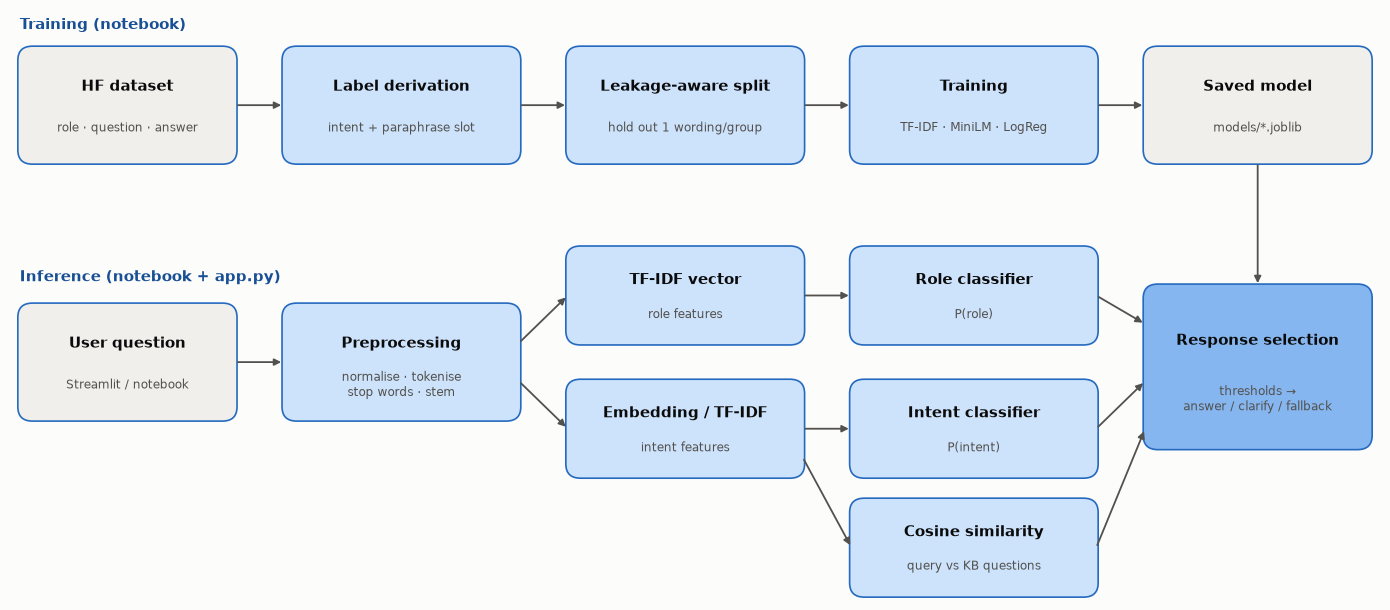

In [42]:
fig, ax = plt.subplots(figsize=(14, 6.2)); ax.set_xlim(0, 14); ax.set_ylim(0, 6.2); ax.axis("off")
def box(x, y, w, h, title, sub="", fc="#cde2fb"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.15", fc=fc, ec="#256abf", lw=1.2))
    ax.text(x + w / 2, y + h * 0.66, title, ha="center", va="center", fontsize=10.5, weight="bold", color=INK)
    if sub: ax.text(x + w / 2, y + h * 0.3, sub, ha="center", va="center", fontsize=8.5, color=INK2)
def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", color=INK2, lw=1.3))

box(0.1, 4.6, 2.2, 1.2, "HF dataset", "role · question · answer", "#f0efec")
box(2.8, 4.6, 2.4, 1.2, "Label derivation", "intent + paraphrase slot")
box(5.7, 4.6, 2.4, 1.2, "Leakage-aware split", "hold out 1 wording/group")
box(8.6, 4.6, 2.5, 1.2, "Training", "TF-IDF · MiniLM · LogReg")
box(11.6, 4.6, 2.3, 1.2, "Saved model", "models/*.joblib", "#f0efec")
for x in (2.3, 5.2, 8.1, 11.1): arrow(x, 5.2, x + 0.5, 5.2)

box(0.1, 1.9, 2.2, 1.2, "User question", "Streamlit / notebook", "#f0efec")
box(2.8, 1.9, 2.4, 1.2, "Preprocessing", "normalise · tokenise\nstop words · stem")
box(5.7, 2.7, 2.4, 1.0, "TF-IDF vector", "role features")
box(5.7, 1.3, 2.4, 1.0, "Embedding / TF-IDF", "intent features")
box(8.6, 2.7, 2.5, 1.0, "Role classifier", "P(role)")
box(8.6, 1.3, 2.5, 1.0, "Intent classifier", "P(intent)")
box(8.6, 0.05, 2.5, 1.0, "Cosine similarity", "query vs KB questions")
box(11.6, 1.6, 2.3, 1.7, "Response selection", "thresholds →\nanswer / clarify / fallback", "#86b6ef")
arrow(2.3, 2.5, 2.8, 2.5); arrow(5.2, 2.7, 5.7, 3.2); arrow(5.2, 2.3, 5.7, 1.8)
arrow(8.1, 3.2, 8.6, 3.2); arrow(8.1, 1.8, 8.6, 1.8); arrow(8.1, 1.5, 8.6, 0.55)
arrow(11.1, 3.2, 11.6, 2.9); arrow(11.1, 1.8, 11.6, 2.3); arrow(11.1, 0.55, 11.6, 1.8)
arrow(12.75, 4.6, 12.75, 3.3)
ax.text(0.1, 6.0, "Training (notebook)", fontsize=11, weight="bold", color="#184f95")
ax.text(0.1, 3.35, "Inference (notebook + app.py)", fontsize=11, weight="bold", color="#184f95")
plt.tight_layout(); plt.show()

## 17. Conclusion

In [43]:
summary = pd.Series({
    "Role accuracy (test)": cls_table.loc["Role classifier (54 classes)", "accuracy"],
    "Intent accuracy (test)": cls_table.loc["Intent classifier (10 classes)", "accuracy"],
    "Intent macro-F1 (test)": cls_table.loc["Intent classifier (10 classes)", "macro_f1"],
    "TF-IDF retrieval Hit@1 (test)": e2e.loc["Retrieval only: TF-IDF cosine", "Hit@1"],
    "MiniLM retrieval Hit@1 (test)": e2e.loc["Retrieval only: MiniLM cosine", "Hit@1"],
    "Hybrid Hit@1 (test)": pt.correct.mean(),
    "Hybrid Hit@1 (3-fold CV mean)": cv["hybrid Hit@1"].mean(),
    "Coverage with thresholds (test)": system["coverage (answered)"],
    "Accuracy of answered (test)": system["accuracy of answered"],
    "OOD fallback rate (hand-written test)": system["OOD test: fallback rate"],
    "Realistic probe answered correctly": probe.answered_correctly.mean(),
}, name="value")
summary.round(3).to_frame()

,value
Role accuracy (test),1.000
Intent accuracy (test),0.715
Intent macro-F1 (test),0.646
TF-IDF retrieval Hit@1 (test),0.293
MiniLM retrieval Hit@1 (test),0.700
Hybrid Hit@1 (test),0.715
Hybrid Hit@1 (3-fold CV mean),0.829
Coverage with thresholds (test),0.987
Accuracy of answered (test),0.720
OOD fallback rate (hand-written test),1.000


**Summary.** We built a career-guidance chatbot from a Hugging Face QA dataset with a complete NLP pipeline:
data-quality checks, a verified derived intent label, text preprocessing, TF-IDF and sentence-embedding features,
Logistic Regression classifiers, cosine-similarity retrieval, and threshold-based clarification and fallback.
The model was evaluated on question wordings never seen in training, and the same saved model powers the
Streamlit app.

**Key findings (table above)**
- **Role** prediction is essentially solved by TF-IDF + Logistic Regression, because questions name the role.
- **Intent** on unseen wordings is the real challenge. TF-IDF features cannot connect words like *salary* and
  *earn*, while pretrained **MiniLM sentence embeddings** roughly double TF-IDF retrieval accuracy. This was the
  main design decision, and it was made on validation data only.
- The **hybrid model** (role classifier + embedding intent classifier + in-group cosine selection) is at least as
  accurate as the best retrieval-only baseline. It also produces calibrated signals that let the bot ask for
  clarification when no role is given and fall back on out-of-scope questions; it did so in every hand-written test case.
- **Remaining errors** come mostly from intents whose wordings genuinely overlap (skills ↔ tools, education ↔
  getting started). Those errors are confident, so thresholds do not catch them; more paraphrases or a revised
  label scheme would address them (Section 15).

**Takeaway.** Use lexical features where the signal is lexical (role names) and semantic features where meaning
matters (intent). Evaluate with a split that tests the generalisation you actually need (new wordings), and report
where the model fails as well as where it succeeds.